<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/sungwook/advanced/sungwook/session03/4%EC%B0%A8%EC%8B%9C_%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **딥러닝 2. FOCUS ON TRANSFORMER**

## **1. 인트로**

### **1-1. RNN의 한계와 어텐션의 등장**

#### **Attention의 등장배경 : Seq2Seq의 병목 현상**

기존 모델 Seq2Seq은 Context Vector의 크기가 고정되어 있어 입력이 5단어든 50단어든 같은 크기의 벡터에 모든 정보를 담아야 합니다. 디코더는 이 Context Vector 하나만을 이용해 출력 문장을 생성하기 때문에 문장이 길어질수록 정보손실의 문제가 발생한다.

또한 디코더는 “나는”을 만들 때도, “수학을”을 만들 때도 똑같은 요약본을 참고하여 출력 단어마다 필요한 정보를 다르게 반영할 수 없습니다.

게다가 Context Vector는 인코더의 마지막 hidden state이므로 마지막 단어의 정보는 진하게 남지만 앞쪽 단어 정보는 여러 단계를 거치며 희미해집니다.

**그래서 이러한 한계를 해결하기 위해 등장 한 것이 Attention!!**

Attention은 디코더가 단어를 생성할 때마다 입력 문장 전체를 다시 보고, 현재 단어와 관련 있는 부분에 집중하여 출력 단어마다 새로운 Context Vector를 만듭니다.

#### **Attnetion의 정의**
- 현재 시점에서 가장 중요한 부분에 더 높은 가중치를 부여하는 기술
- 출력 단어를 생성할 떄 입력 문장 속 단어들 중 어떤 단어에 더 집중할지의 정도를 결정

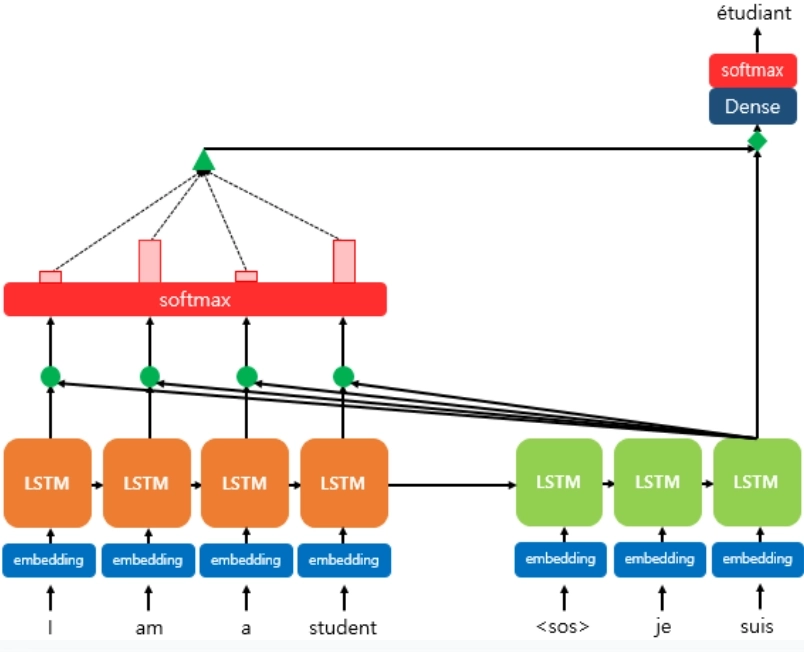

- **해석**
  - 인코더 (주황색) : “I, am, a, student”를 LSTM에 넣어 순서대로 읽으며 단어마다 그 시점에 의미를 담은 hidden state를 생성합니다.
  기존 Seq2Seq와 달리, 마지막 hidden state 하나가 아니라 4개의 hidden state를 모두 남겨둡니다.
  - 디코더 (초록색) :  <sos> 토큰에서 시작해 “je”, “suis”를 차례대로 생성했으며, 현재는 다음 단어를 예측하는 시점입니다.
  - Attention
    - 초록원 : 디코더의 현재 상태(state)를 인코더의 각 hidden state와 비교하여 각각 관련도 점수를 계산
    - Softmax : 계산된 점수들을 합이 1인 확률 분포, 즉 어텐션 가중치로 변환합니다. 분홍막대를 통해 ‘student’ 단어에 해당하는 막대가 가장 관련 점수가 높다는 것을 확인 가능
    - 초록 삼각형 : 이 비율을 섞어 현재 필요한 정보만 모아 요약한 Context Vector를 생성
  - 출력 : 디코더 상태와 Context Vector를 합친 뒤, Dense 레이어와 Softmax를 거쳐 étudiant(학생) 을 출력합니다.    

**기존 Seq2Seq는 원문 정보를 순차적으로 전달받은 결과만 사용하는 반면 Attention은 디코더와 인코더의 모든 위치를 직접 비교합니다.**

#### **Attention의 과정**

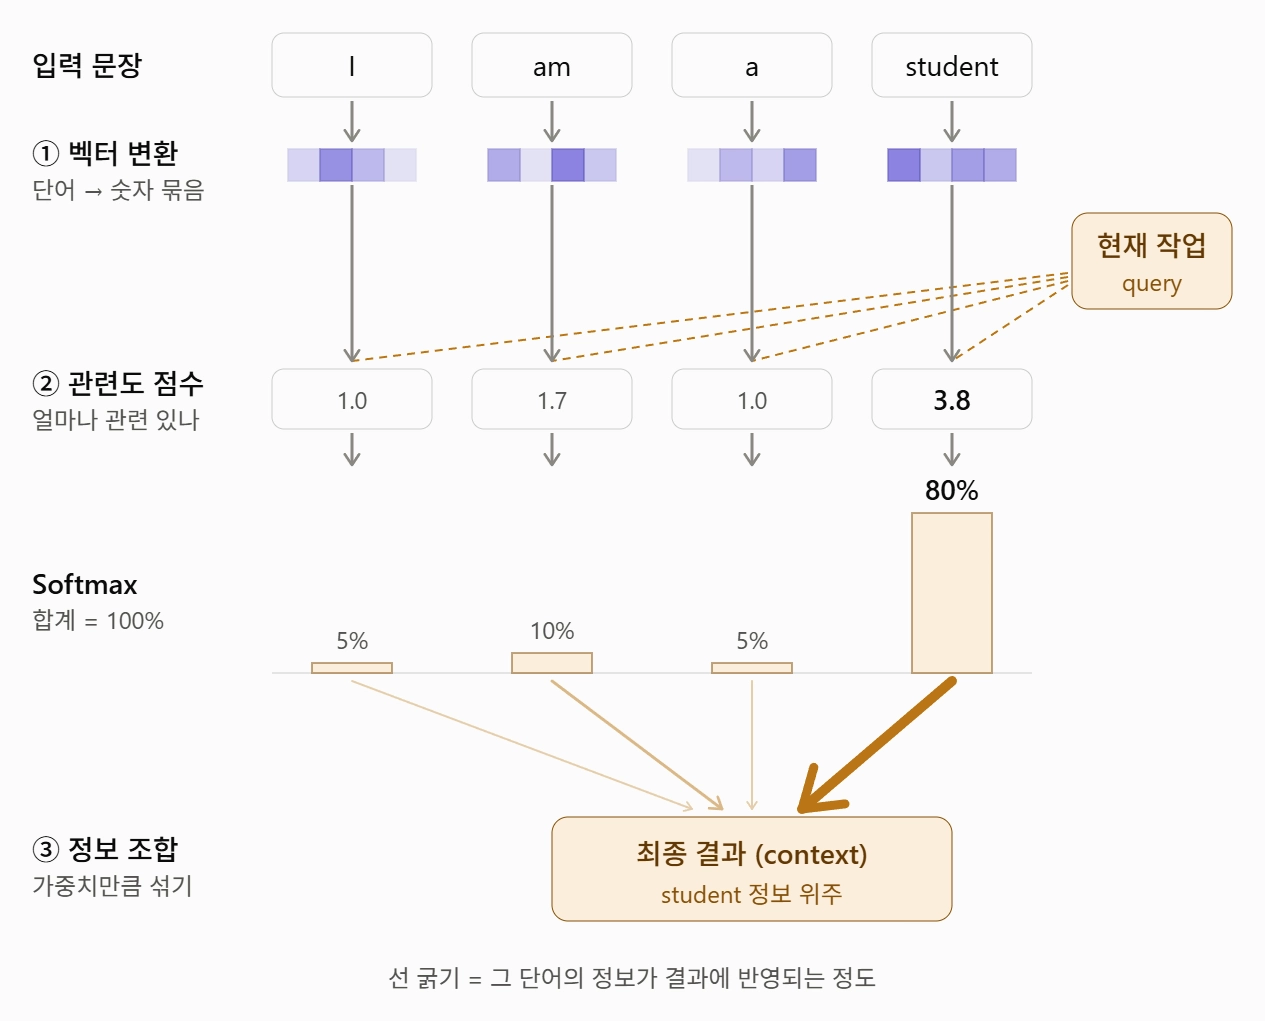

1. 입력을 벡터 형태로 변환 :
    
    입력 단어를 컴퓨터가 읽을 수 있도록 숫자로 이루어진 벡터로 변환!
    
2. 단어별 중요도 계산 :
    - **관련도 점수** - 현재 작업과 각 단어 사이의 관계가 얼마나 관련이 높고 유사한지 점수를 매김!
    - **Softmax** - 관련도 점수를 0~1 사이의 확률 값으로 변환! 모든 단어의 중요도 합이 1인 비율로 바꿔주는 함수이고 이 Softmax를 거친 비율을 **Attention Weight(어텐션 가중치)라고 함.**
   
    → 그림을 보면, student는 3.8점의 관련도 점수를 받았고, Softmax를 거쳐 80%의 가중치가 됩니다. 즉 모델이 ***"student 단어에 80%를 집중하겠다"*** 고 판단한 것!

3. 중요도에 따른 입력 정보 조합 :
    
    어텐션 가중치(비율)만큼 각 단어의 hidden state 정보를 섞어 Context Vector 생성! 이 과정에서 **가장 비율이 높은 단어 정보**를 위주로 반영하여 다음 결과를 구성하게 됨.

#### **Attention 매커니즘 장점**
1. **시간 경과에 대한 유연성 (vs. RNN)**
    - RNN은 정보를 한 단계씩 전달하기 때문에 멀리 떨어진 단어일수록 정보가 흐려지는 **장기 의존성 문제**가 있습니다.
    - 반면, Attention은 모든 단어를 직접 비교하므로 거리와 상관없이 관계 파악이 가능합니다.
    
2. **공간에 대한 유연성 (vs. CNN)**
    - CNN은 고정된 크기의 필터로 **주변 정보만** 보며, 멀리 있는 정보를 연결하려면 층을 여러 번 쌓아야 합니다.
    - Attention은 모든 위치를 직접 연결하여 **한 번에 전역적인 관계**를 학습할 수 있습니다.

3. **병렬화 (vs. RNN)**
    - RNN은 앞 단계가 끝나야 다음 단계를 계산하는 순차 구조라 학습이 느립니다.
    - Attention의 관련도 계산은 각 단어 쌍마다 **서로 독립적**이므로 동시에 계산 가능합니다. → RNN을 완전히 제거한 **Transformer**에서 온전히 발휘

#### **정리**

| **모델** | **한계** |  |
| --- | --- | --- |
| RNN | 장기 의존성 문제 + 병렬화 불가 |  |
| LSTM | 장기 의존성은 완화했지만, 순차 구조는 그대로 |  |
| Seq2Seq + Attention | 병목 현상은 해결했지만, 여전히 RNN 위에서 작동하는 **보조 역할** |  |



### **1-2. Attnetion is All You Need**

#### **Transformer 구조를 처음 발표한 논문 (Self-Attnetion 방식)**
- 2017년 NIPS에서 Google Brain·Google Research 연구진 8명이 발표
- 제목 그대로 “Attention만 있으면 된다”는 주장을 담은 논문
    
    **⇒ 오늘날 LLM의 기반이 된 논문!**

#### **간단 소개**
1. **논문 배경 : RNN과 RNN기반 모델들의 한계**
  - RNN, LSTM, GRU : 당시 시퀀스 작업의 표준 모델. 하지만 순차적 구조의 한계를 가짐. -> 한 문장 안에서 병렬 처리가 불가능!
  - Attention은 거리 상관없이 단어 관계를 잘 잡는 도구로 쓰였지만, RNN의 보조적 역할에 불과!

2. **Transformer의 등장**
  - 본 논문에서는 RNN과 CNN을 완전히 제거하고 Self-Attention으로 입력 출력 관계를 계산하는 **Transformer 모델** 제안!!

3. **논문 속 중요 발견**
  - Recurrence(순환)와 Convolution(합성곱)은 필수가 아니다
  - 이 논문에서는 Attention만으로 더 좋은 성능을 낼 수 있고, 순차 구조를 없앤 덕분에 **병렬화를 통한 빠른 학습 속도가 가능**해짐!!

4. **파급효과**
- **LLM의 탄생** : Transformer의 디코더를 쌓은 GPT, 인코더를 쌓은 BERT가 등장하며 오늘날 대형 언어 모델의 기반이 됨
- **NLP 평정** : 번역, 요약, 질의응답 등 자연어 처리 대부분의 표준 구조로 자리잡음
- **타 분야로의 확장** : 이미지, 음성 등으로 확장. 논문 결론에서도 저자들은 이미지·오디오·비디오의 확장을 향후 계획으로 언급

#### **Transformer란?**
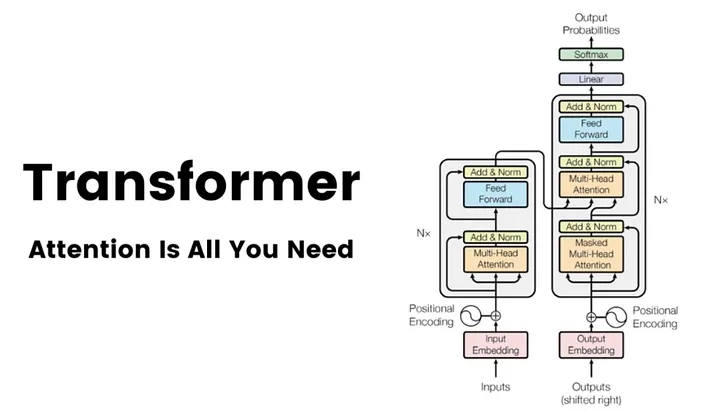

#### **정의**

RNN처럼 단어를 순서대로 처리하지 않고 **Attention 만으로 문장 전체의 의미와 구조를 파악하여 한 번에 처리**하는 **인코더-디코더 모델**

#### **구조**

기존 모델과 Transformer의 차이는 ***인코더와 디코더 내부를 무엇으로 채워 구조(부품)를 만들었는가!***

| **구분** | **Seq2Seq + Attention** | **Transformer** |
| --- | --- | --- |
| 인코더, 디코더의 내부 | LSTM (순차 처리) | Self-Attention |
| 어텐션의 역할 | RNN을 돕는 보조 역할 | 모델 그 자체 |
| 어텐션 사용 위치 | 디코더 → 인코더 1곳 | 인코더 내부, 디코더 내부, 인코더-디코더 사이 3곳 |
| 단어 순서 정보 | RNN이 순서대로 읽으며 반영 | Positional Encoding으로 따로 추가 |
| 병렬 처리 | 불가 | 가능 |

#### **핵심 기술**
- **Self-Attention** : 문장 안의 단어들이 서로를 참고해 얼마나 중요한 관계를 맺고있는지 한 번에 문맥을 파악하는 기술
- **Multi-Head Attention** : Attention을 여러 갈래로 나눠 다양한 관점에서 관계를 파악함
- **Positional Encoding** : 각 단어의 위치를 벡터로 만들어 단어 벡터에 더함으로써, 사라진 순서 정보를 보완


## **2. Self-Attention**

### **2-1. Query, Key, Value**

#### **Q, K, V 개념**

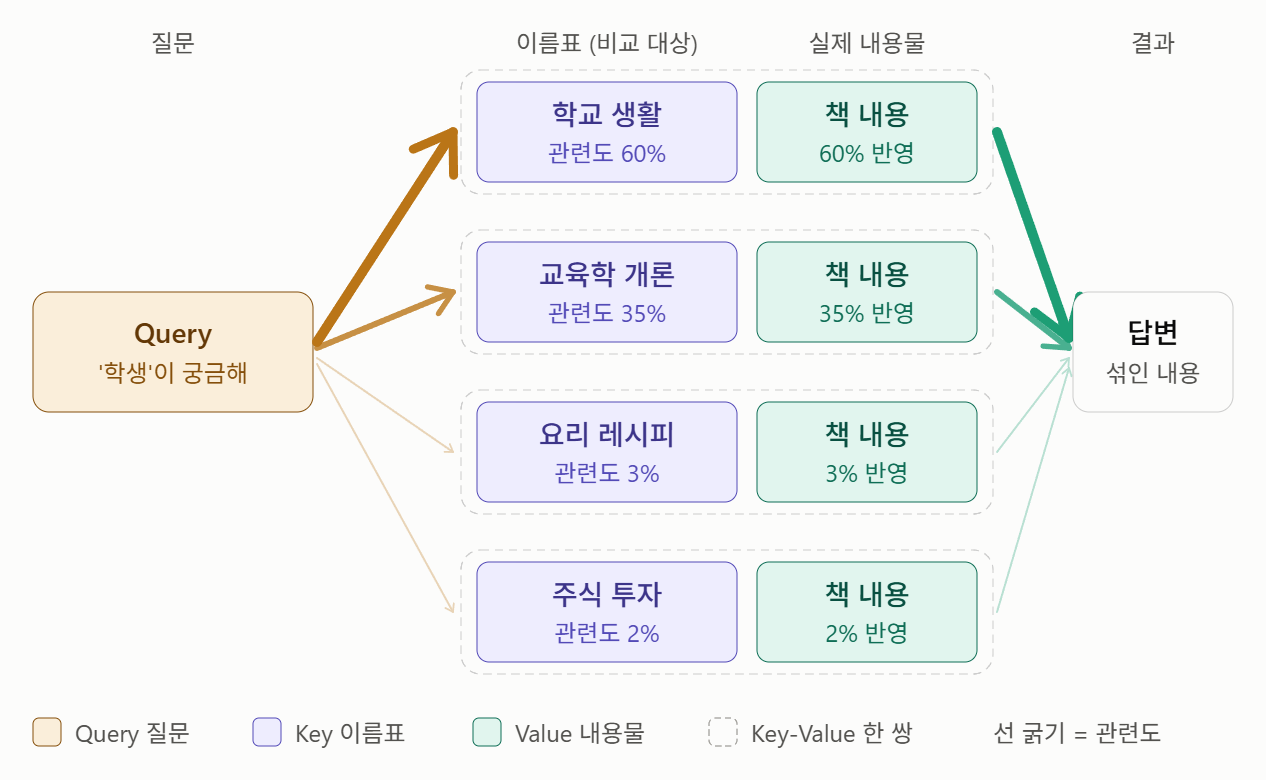

#### **Attention은 Query를 Key들과 비교해 관련도를 구하고 그 비율만큼 Value를 섞어 결과를 만드는 계산!**

- **Q : Query(쿼리)**
    
    현재 처리 중인 단어가 다른 단어들에게 “지금 나한테 필요한 정보가 뭐지?”라고 묻는 벡터
    
    - 예시
        - 도서관 예시) “’학생’에 대해 알고 싶어” 라는 궁금증

- **K : Key(키)**
    
    각 단어가 “나는 이런 정보를 가지고 있어” 라고 보이는 벡터. 즉, 키는 검색 대상이 되는 모든 정보의 ‘이름표’
    
    Query와 비교하여 관련도 점수를 결정
    
    - 예시
        
        ‘학교 생활’, ‘교육학 개론’, ‘요리 레시피’, ‘주식 투자’ 제목표 → ‘학생’과 비교하여, 60%, 35%, 3%, 2%
        
- **V : Value(밸류)**
    
    각 단어가 실제로 전달하는 정보 벡터. 관련도 비율만큼 모든 Value를 섞어 최종 결과를 만듦
    
    - 예시
        
        학교 생활 책 내용 60% + 교육학개론 35% + 요리 레시피 3% + 주식투자 2% → 최종 답변
        
- **Key - Value 사이의 관계**
    
     Key와 Value는 하나의 단어에서 함께 만들어진 한 쌍! Key는 “찾을 때 쓰는 기준”, Value는 “찾았을 때 가져오는 내용”
    
    - Key-Value를 나누는 이유 :

      같은 단어라도 **"무엇과 관련 있는지 판단할 때 필요한 정보"** 와 **"실제로 전달해야할 정보"** 는 다를 수 있기 때문

### **2-2. 기존 Cross-Attention vs. Self-Attention**

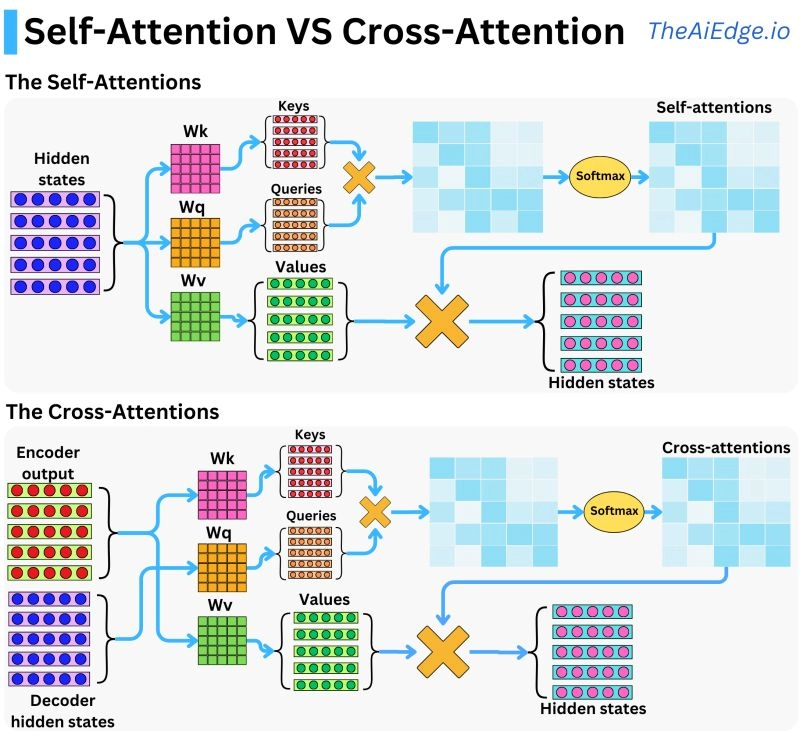

- 그림 해석
    - 공통 흐름 :
        1. 입력을 학습된 변환 Wk, Wq, Wv에 통과시켜 Query, Key, Value 생성
        2. Query x Key(파란격자) → 모든 단어 쌍의 관련도 표
        3. Softmax → 각 줄 합이 1인 비율로 변환. 칸이 진할 수록 많이 참고
        4. 비율 x Value → 새로운 hidden states
    - 차이점 :
        - Self-Attention : Q, K, V가 모두 같은 입력, 즉 같은 hidden states에서 생성
        - Cross-Attention : Q는 디코더, K와 V는 인코더 출력에서 생성

#### **Cross-Attention (기존 Attention in Seq2Seq**

**Query와 Key-Value쌍이 서로 다른 시퀀스에서 출력!**
  - 하나의 시퀀스가 독립된 다른 시퀀스를 참고하여 정보를 만들어내는 매커니즘
  - **디코더가 인코더에게 "지금 어디를 봐야하지?"라고 묻는 참고 구조!**

**핵심 과정**
- 예시 : 원문 “The cat is sleeping” → 번역 중 “고양이가 ____.”, 다음 단어를 만드는 순간

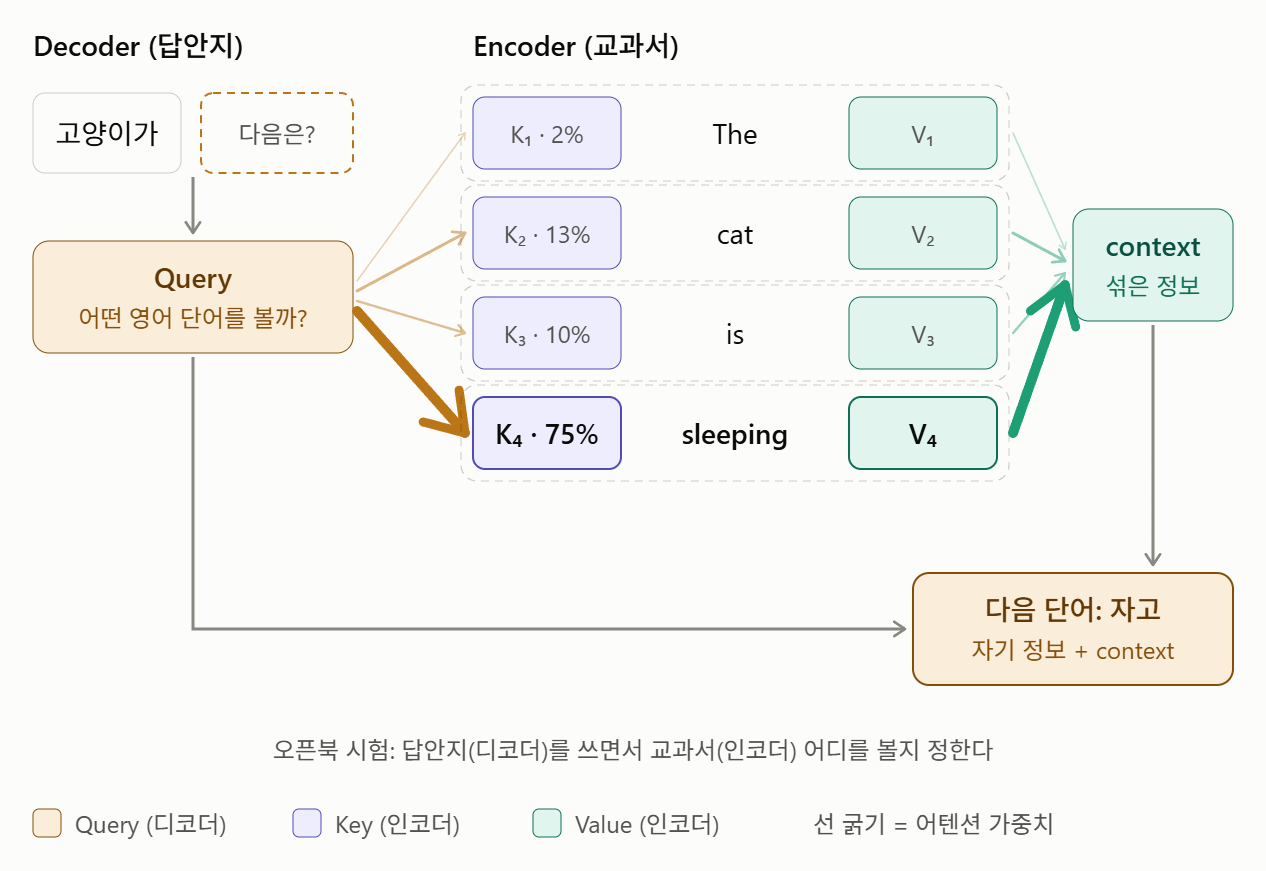

1. **Query 만들기**
    
    디코더가 지금까지 만든 “고양이가”를 바탕으로 현재 상태를 Query로 만듦 → “다음 단어를 위해 어떤 영어 단어를 봐야 할까?”
    
2. **Key, Value 불러오기**
    
    인코더가 원문의 각 단어 (The, cat, is, sleeping)에 대해 만들어 둔 벡터를 Key와 Value로 사용
    
3. **유사도 계산 (Attention Score)**
    
  - 관련도 계산 :
    
  $$
    Q\ \cdot \ K_i \ \ (내적)
  $$
    
  - Query와 각 Key의 관련도를 계산하고 Softmax로 확률의 값 비율로 변환 → The 2%, cat 13%, is 10%, **sleeping 75%**
    
4. **Weighted Sum**
    
    비율만큼 Value를 섞어 Context Vector 생성 → 디코더 자기 정보 + Context Vector로 다음 단어 “자고” 출력

**한계점**

인코더와 디코더가 RNN 위에서 작동하기 때문에 **원문 내부의 관계는 RNN이 순서대로 읽으며 간접적으로 파악하고 병렬 처리 불가하다는 한계**가 존재!

#### **Self-Attention**

**Query와 Key-Value쌍이 같은 시퀀스에서 출력**
  - 문장이 스스로에게 "우리끼리 누가 누구와 관련이 있지?"라고 묻는 구조. RNN 없이도 문장 내부의 관계와 문맥을 직접 파악 가능!

**핵심 과정**  
예시 : “가을 은행 냄새 지독해”에서 ‘은행’의 의미 파악
    
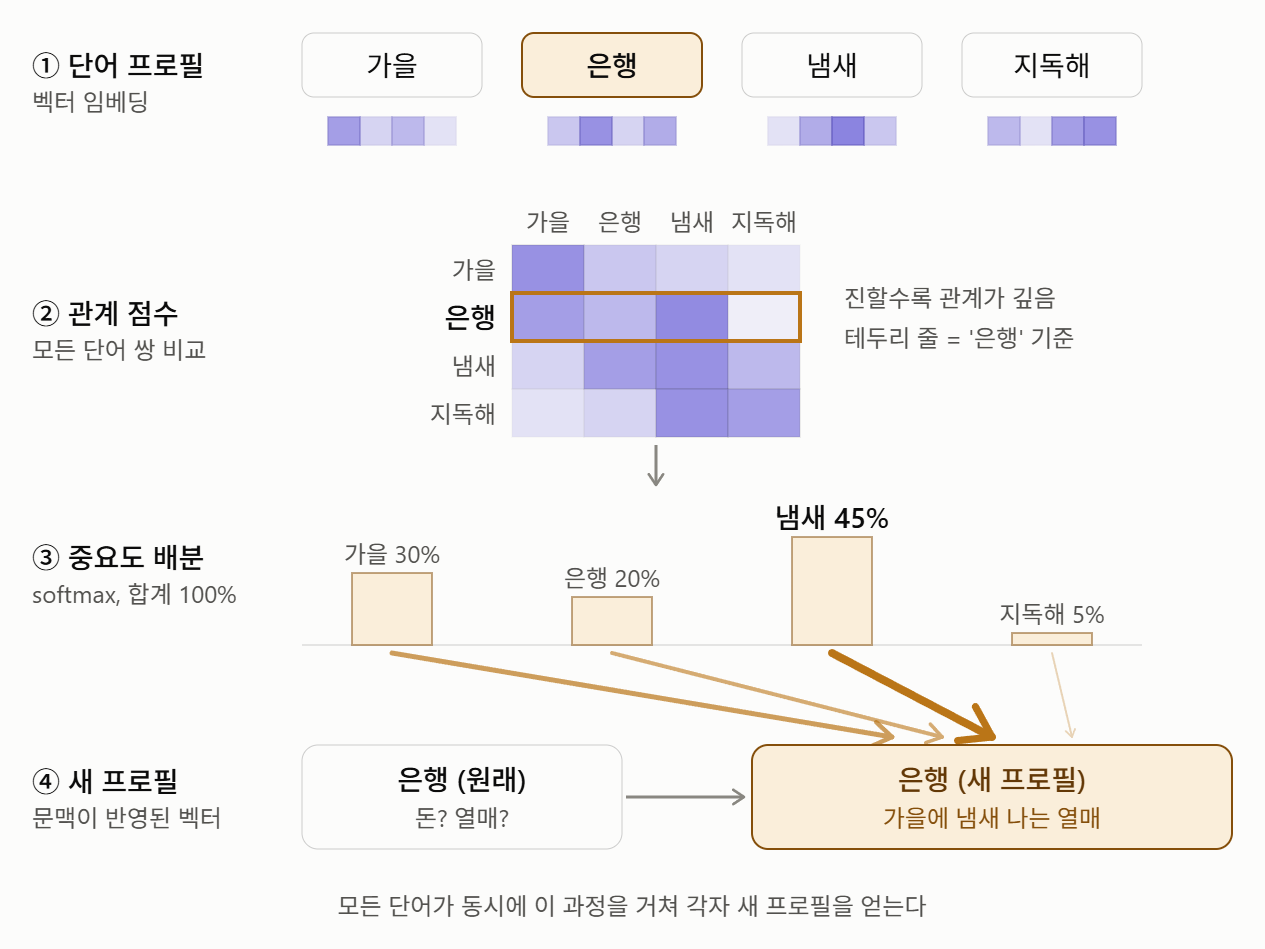
    
1. **벡터 임베딩**
        
    각 단어를 컴퓨터가 읽을 수 있도록 벡터로 변환하고 같은 벡터에서 Q, K, V를 만듦
        
2. **내적 및 관련도 점수**
        
    ‘은행’의 Query와 모든 단어의 Key를 비교해 관계 점수 계산 (가로줄 = 질문하는 단어, 세로줄 = 참고 대상)
        
3. **중요도 배분 (Softmax & 어텐션 가중치)**
        
    가을 30%, 은행 20%, **냄새 45%**, 지독해 5%로 비율 변환 및 특정 단어를 이해에 대한 각각의 %로 중요도 판단
        
4. **새로운 벡터 생성**
        
    비율만큼 Value를 섞어 ‘은행’이 “돈? 열매?”에서 **“가을에 냄새 나는 열매”**라는 의미를 담은 새 벡터가 생성
        

⇒ 이 과정을 모든 단어가 동시에 거쳐 각자 문맥이 반영된 새 벡터를 얻음 → **병렬 처리 가능**

**비교**

| 구분 | Cross-Attention | Self-Attention |
| --- | --- | --- |
| point | 번역 중인 문장이 원문을 참고 | 문장이 스스로 내부 관계를 파악 |
| 작동 방식 | 디코더의 Query로 인코더의 Key, Value를 조회 | 같은 문장에서 만든 Q, K, V로 모든 단어끼리 비교 |
| 참조 대상 | 서로 다른 시퀀스 (디코더 → 인코더) | 서로 같은 시퀀스 (문장 내부) |
| 주요 목적 | 고정 Context Vector의 병목 해결 | 문맥이 반영된 단어 표현 생성 |
| 결과 벡터 | Context Vector | 문맥이 반영된 새 표현 |
| 기반 아키텍처 | RNN | Transformer |
| 병렬처리 | RNN 기반일 때 불가능 | 가능 |

### **2-3. Scaled Dot-Product Attention**

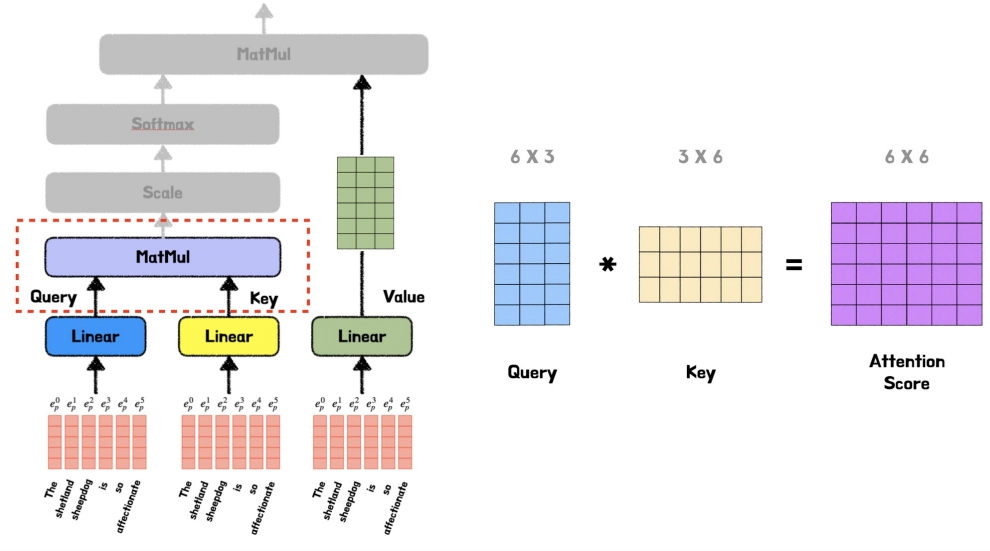

- **Attention Score를 계산하는 가장 기본적인 방법 중 하나!**
  - Query와 Key 벡터를 **내적**하여 관련도 점수를 구하는 방식
  - 내적:
  
    두 벡터의 같은 위치 성분끼리 곱해 모두 더한 값. 방향이 비슷할수록 큰 값 -> "얼마나 닮았나"를 숫자로 표현 한 것
  $$
Q \cdot K = \sum_{i=1}^{d_k} Q_iK_i
$$
  
**기본적인 과정**

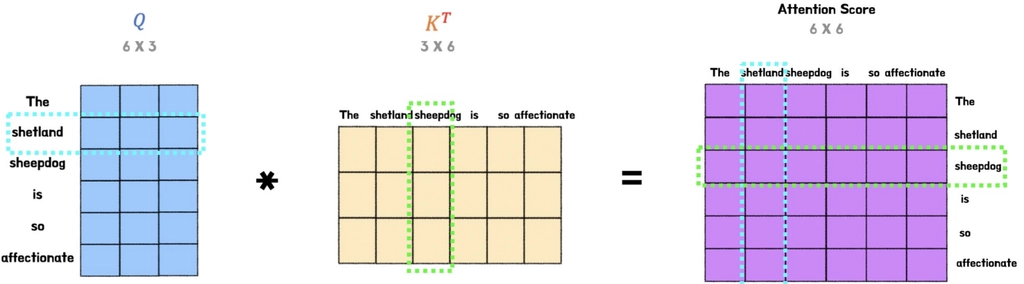

1. **Attention Score 계산**
    - Query (6x3)와 전치한 Key (3x6)를 곱함
    - 결과 (6x6) : 모든 단어 x 모든 단어의 관련도 점수표
    - 행렬 곱셈 한 번으로 36개 점수를 **동시에** 계산 -> 병렬 처리가 실제로 구현되는 지점
    - 계산된 Attention Score 표 읽는 법
        
        가로줄 = 질문하는 단어
        
        세로줄 = 참고 대상 단어

2. **계산된 값에 Softmax 적용 -> Attention Weight 산출**

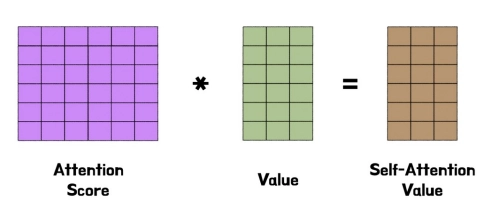

- 점수표의 각 가로줄을 합이 1인 비율로 전환
- "이 단어는 다른 단어들을 몇 %씩 참고하는가"를 나타냄

3. **최종 결과값 계산**
- Attention Weight(6x6) x Value → 각 단어가 다른 단어 정보를 비율만큼 섞은 새 벡터 6개 (행 기준)

**문제점 : Attention Score의 극단화**

벡터 차원이 커질수록 내적(Dot Product) 값이 지나치게 커질 수 있음. 이러한 극단적인 값이 Softmax 함수에 입력되면 특정 단어에 확률이 과도하게 몰리는 현상 발생! 이로 인해 기울기가 0에 가까워져 학습이 원활하게 진행되지 않는 Vanishing Gradient 문제 발생 가능!

#### **Scaled Dot-Product Attention**
**Transformer의 Attention 계산 공식 그 자체**

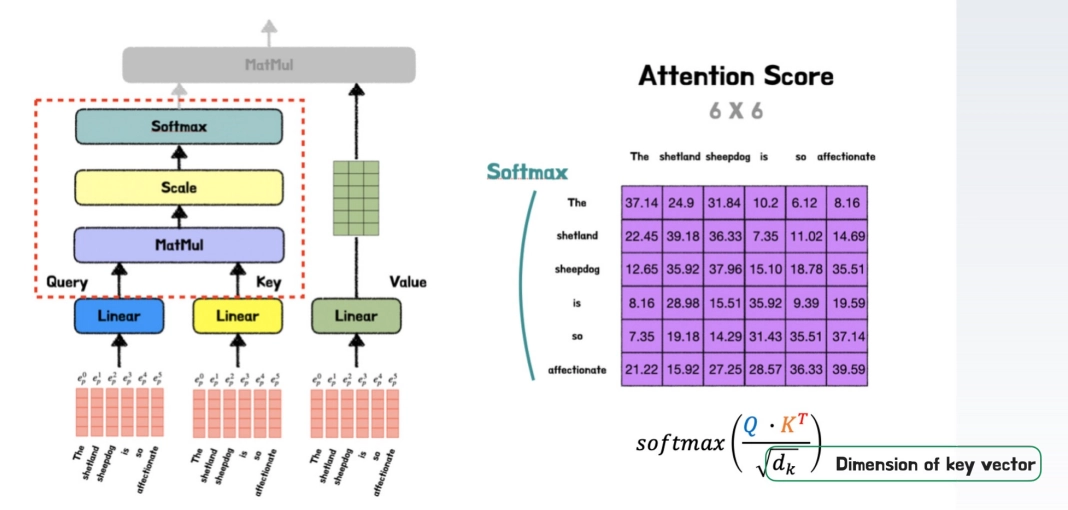

**기존의 Dot-Product Attention 문제를 해결한 방법!**

내적과 Softmax 사이에 **스케일링 단계 하나 추가!**

- **과정**
  1. Query와 모든 Key를 내적 → Attention Score
  2. Attention Score를 $\sqrt{d_k}$로 나누는 스케일링 과정 진행
  3. Softmax 적용 → Attention Weight 산출
  4. Attention Weight x Value → 최종 결과

- $\sqrt{d_k}$로 나누면 분산이 다시 1 근처로 돌아와, 차원의 크기와 상관없이 점수가 안정적인 범위에 머물 수 있게 됩니다!
    - (예시)스케일링 효과
        
        
        |  | the | shetland | sheepdog | is | so | affectionate |
        | --- | --- | --- | --- | --- | --- | --- |
        | 스케일링 전 | 0% | 10.7% | 82.2% | 0% | 0% | 7.1% |
        | 스케일링 후 | 0% | 19.9% | 64.5% | 0% | 0% | 15.7% |
        
        ⇒ 스케일링 전에는 sheepdog 하나에 82%가 몰리지만, 스케일링 후에는 shetland, affectionate에도 비율이 나눠져 주변 정보를 고르게 반영


- **Scaled Dot-Product Attention 함수 수식**
    
    $$
    Attention(Q,K,V)=softmax(\frac{QK^T}{\sqrt{d_K}})V
    $$
    
    - $QK^T$ : 모든 Query와 Key의 내적 → 관련도 점수표
    - $\sqrt{d_k}$ : 점수 크기 조정 (Scaling)
    - $V$ : 비율만큼 Value를 섞어 결과 생성

**Scaled Dot-Product Attention 계산의 결과로 얻어지는 벡터**

- Cross-Attention : Context Vector
    
    현재 생성 중인 단어에 필요한 원문 정보를 비율만큼 모은 벡터
    
- Self-Attention
    
    문장 내 다른 단어들과의 관계가 반영되어 **의미가 업데이트**된 단어 벡터    

## **3. Multi-Head Attention**

### **3-1. 왜 Multi-Head Attention을 사용할까?**

#### **Single-head Attention vs. Multi-Head Attention**
- 헤드(Head)란?
  - Attention 계산을 **한 번 하는 독립된 단위**
  - 헤드마다 가중치 행렬의 숫자가 다르기 떄문에, 같은 문장을 봐도 집중하는 단어가 달라짐!

**Single-Head Attention (헤드가 1개)**

- 가중치 행렬 세트 하나로, 512차원 벡터를 그대로 한번 Attention진행. 그 결과 단어마다 가중치 분포가 딱 하나 나옴!
- 방식
    1. 각 단어의 512차원 벡터에 가중치 행렬 $W^Q, W^K, W^V$를 한 세트만 곱해서 Q, K, V를 만듭니다.
    2.  Q, K로 점수를 매기고 $\sqrt{d}$로 나눈 뒤 Softmax를 적용하여 가중치 분포 하나를 얻습니다. (이 분포의 합은 1(100%))
    3. 이 가중치로 V를 섞어서 새 512차원 벡터 하나를 출력합니다.

- **한계 : 집중력 100%를 혼자 나눠 써야 한다!**

  Softmax 거친 가중차는 합이 항상 1(100%)! 그런데 한 단어를 이해하려면 여러 종류 관계가 동시에 필요한 경우가 많음

  헤드가 하나뿐이면 이 100%를 여러 관계에 골고루 나눠 줄 수밖에 없고, 결과는 여러 정보가 섞여 **흐릿해진 벡터 하나**!

- 예시 : “Tom gave Mary a book yesterday”

  | 단어 | Tom | Mary | a | book | yesterday |
  | --- | --- | --- | --- | --- | --- |
  | “gave”의 가중치 | 0.25 | 0.25 | 0.02 | 0.25 | 0.23 |

  네 단어가 다 중요하니 비슷하게 나눠 줄 수 밖에 없습니다 !

  → 그러면 준 사람이 Tom이야, Mary야? 흐려지게 됩니다.


**Multi-Head Attention (Attention을 작게 쪼개서 여러 번 동시에 하는 방식)**

- **방식**
  1. 512차원 벡터에 **헤드마다 다른** $W^Q, W^K, W^V$를 곱해서 64차원 Q, K, V를 **8세트** 만듭니다.
  2. 8개 헤드가 서로 간섭하지 않고 각자 Attention을 계산합니다. (가중치 분포가 8개 나오게 됨)
  3.  8개의 64차원 결과를 이어 붙여(Concat) 다시 512차원으로 만듭니다.
  4.  마지막으로 $W^O$를 곱해서 8개의 관점을 하나로 섞습니다.


- 예시 : “Tom gave Mary a book yesterday”

  Multi-Head Attention: 헤드마다 각자 100%를 쓴다.

  | 헤드 | 주로 보는 단어 | 가중치 | 담당하는 질문 |
  | --- | --- | --- | --- |
  | 헤드 1 | Tom | 0.90 | Who? |
  | 헤드 2 | Mary | 0.90 | To whom? |
  | 헤드 3 | book | 0.90 | What? |
  | 헤드 4 | yesterday | 0.90 | When? |

  헤드마다 질문 하나에 집중하고, 결과를 **나란히 이어 붙이기** 때문에 네 정보가 섞이지 않고 또렷하게 남는다!
  


### **3-2. Multi-Head Attention 작동 방식**

- “I love you”에서 love 한 단어가 Multi-Head Attention을 통과하는 과정을 통해 작동 방식을 알아보자!
- 각 단어의 차원, 어텐션 헤드의 수, 각 헤드의 차원은 *Attention is all you need* 논문과 같이 각각 512차원, 8개, 64차원이라 가정.

#### **전체 흐름 4단계**

| 단계 | 하는 일 | 크기 변화 | 기자 비유 |
| --- | --- | --- | --- |
| ① 분할(Projection) | 헤드마다 다른 W를 곱해 작은 Q·K·V를 만듦 | 512 → 64 × 8세트 | 기자 8명에게 취재 수첩 배분 |
| ② 병렬 어텐션 계산 (Attention) | 8개 헤드가 동시에, 서로 간섭 없이 Attention 계산 | 64 × 8개 결과 | 각자 자기 분야 취재 |
| ③ 결합 (Concat) | 8개 결과를 한 줄로 연결 | 64 × 8 → 512 | 기사 8편을 한 묶음으로 |
| ④ 최종 투영 (Final Projection) | $W^O$를 곱해 8개 관점을 하나로 융합 | 512 → 512 | 편집장이 한 기사로 다듬기 |


1. **분할 (Projection) - 8개의 관점 만들기**

love라는 단어를 나타내는 512차원 벡터 하나에 헤드마다 다른 가중치 행렬을 곱해, 64차원짜리 Q·K·V를 8세트 만들기!

| **헤드** | **Query** | **Key** | Value |
| --- | --- | --- | --- |
| 헤드 1 | love × $W_1^Q$ → 64차원 | love × $W_1^K$ → 64차원 | love × $W_1^V$ → 64차원 |
| 헤드 2 | love × $W_2^Q$ → 64차원 | love × $W_2^K$ → 64차원 | love × $W_2^V$ → 64차원 |
| … | … | … | … |
| 헤드 8 | love × $W_8^Q$ → 64차원 | love × $W_8^K$ → 64차원 | love × $W_8^V$ → 64차원 |
  
  문장에 다른 단어 (I, you)도 똑같이 8세트 만들어짐

2. **병렬 어텐션 계산(Attention) - 각 헤드별 각자 분석**

8개 헤드가 서로 간섭하지 않고 동시에 Scaled Dot-Product Attention을 계산함!

헤드 1 안에서는 다음과 같은 일 발생
  <aside>

1. **점수 매기기 (Score):**
    
    love의 $Q_1$ 을 I, love, you의 $K_1$과 각각 내적하여 관련도 점수 3개를 계산합니다.
    
2. **크기 조절 (Scale):**
    
    계산된 점수를 각 헤드 차원의 제곱근 ($\sqrt{64} = 8$)으로 나눠줍니다. (점수가 너무 커져 한 단어가 독차지하는 것을 막음)
    
3. **가중치 변환 (Softmax):**
    
    조절된 점수들에 Softmax를 적용하여 합이 1인 어텐션 가중치를 만듭니다.
    
    → 예: I 0.2, love 0.7, you 0.1
    
4. **섞기 (Weighted Sum):**
    
    이 가중치대로 I, love, you의 $V_1$에 곱해서 모두 더하면 헤드 1의 결과 (64차원)가 나오게 됩니다.

헤드 2~8도 각자의 Q·K·V로 같은 계산을 **동시에, 독립적으로** 진행! → 64차원 결과 8개

3. **이어 붙이기 (Concat)**

8개의 64차원 결과를 순서대로 한 줄로 이어 붙여 512차원(8×64) 벡터를 하나 만들기!

4. **섞기 (Final Projection)**

이어 붙인 벡터는 아직 각 헤드의 분석 결과를 단순히 나열한 것입니다. 따라서 이 벡터에 또 하나의 행렬  
$𝑊
O$ (512×512)를 곱해, 8개 관점을 하나의 의미로 융합!


⇒ **모든 단계가 끝나면 ‘love’라는 단어에 대한 Multi-Head Attention 레이어의 최종 출력 벡터를 얻게 됩니다.**

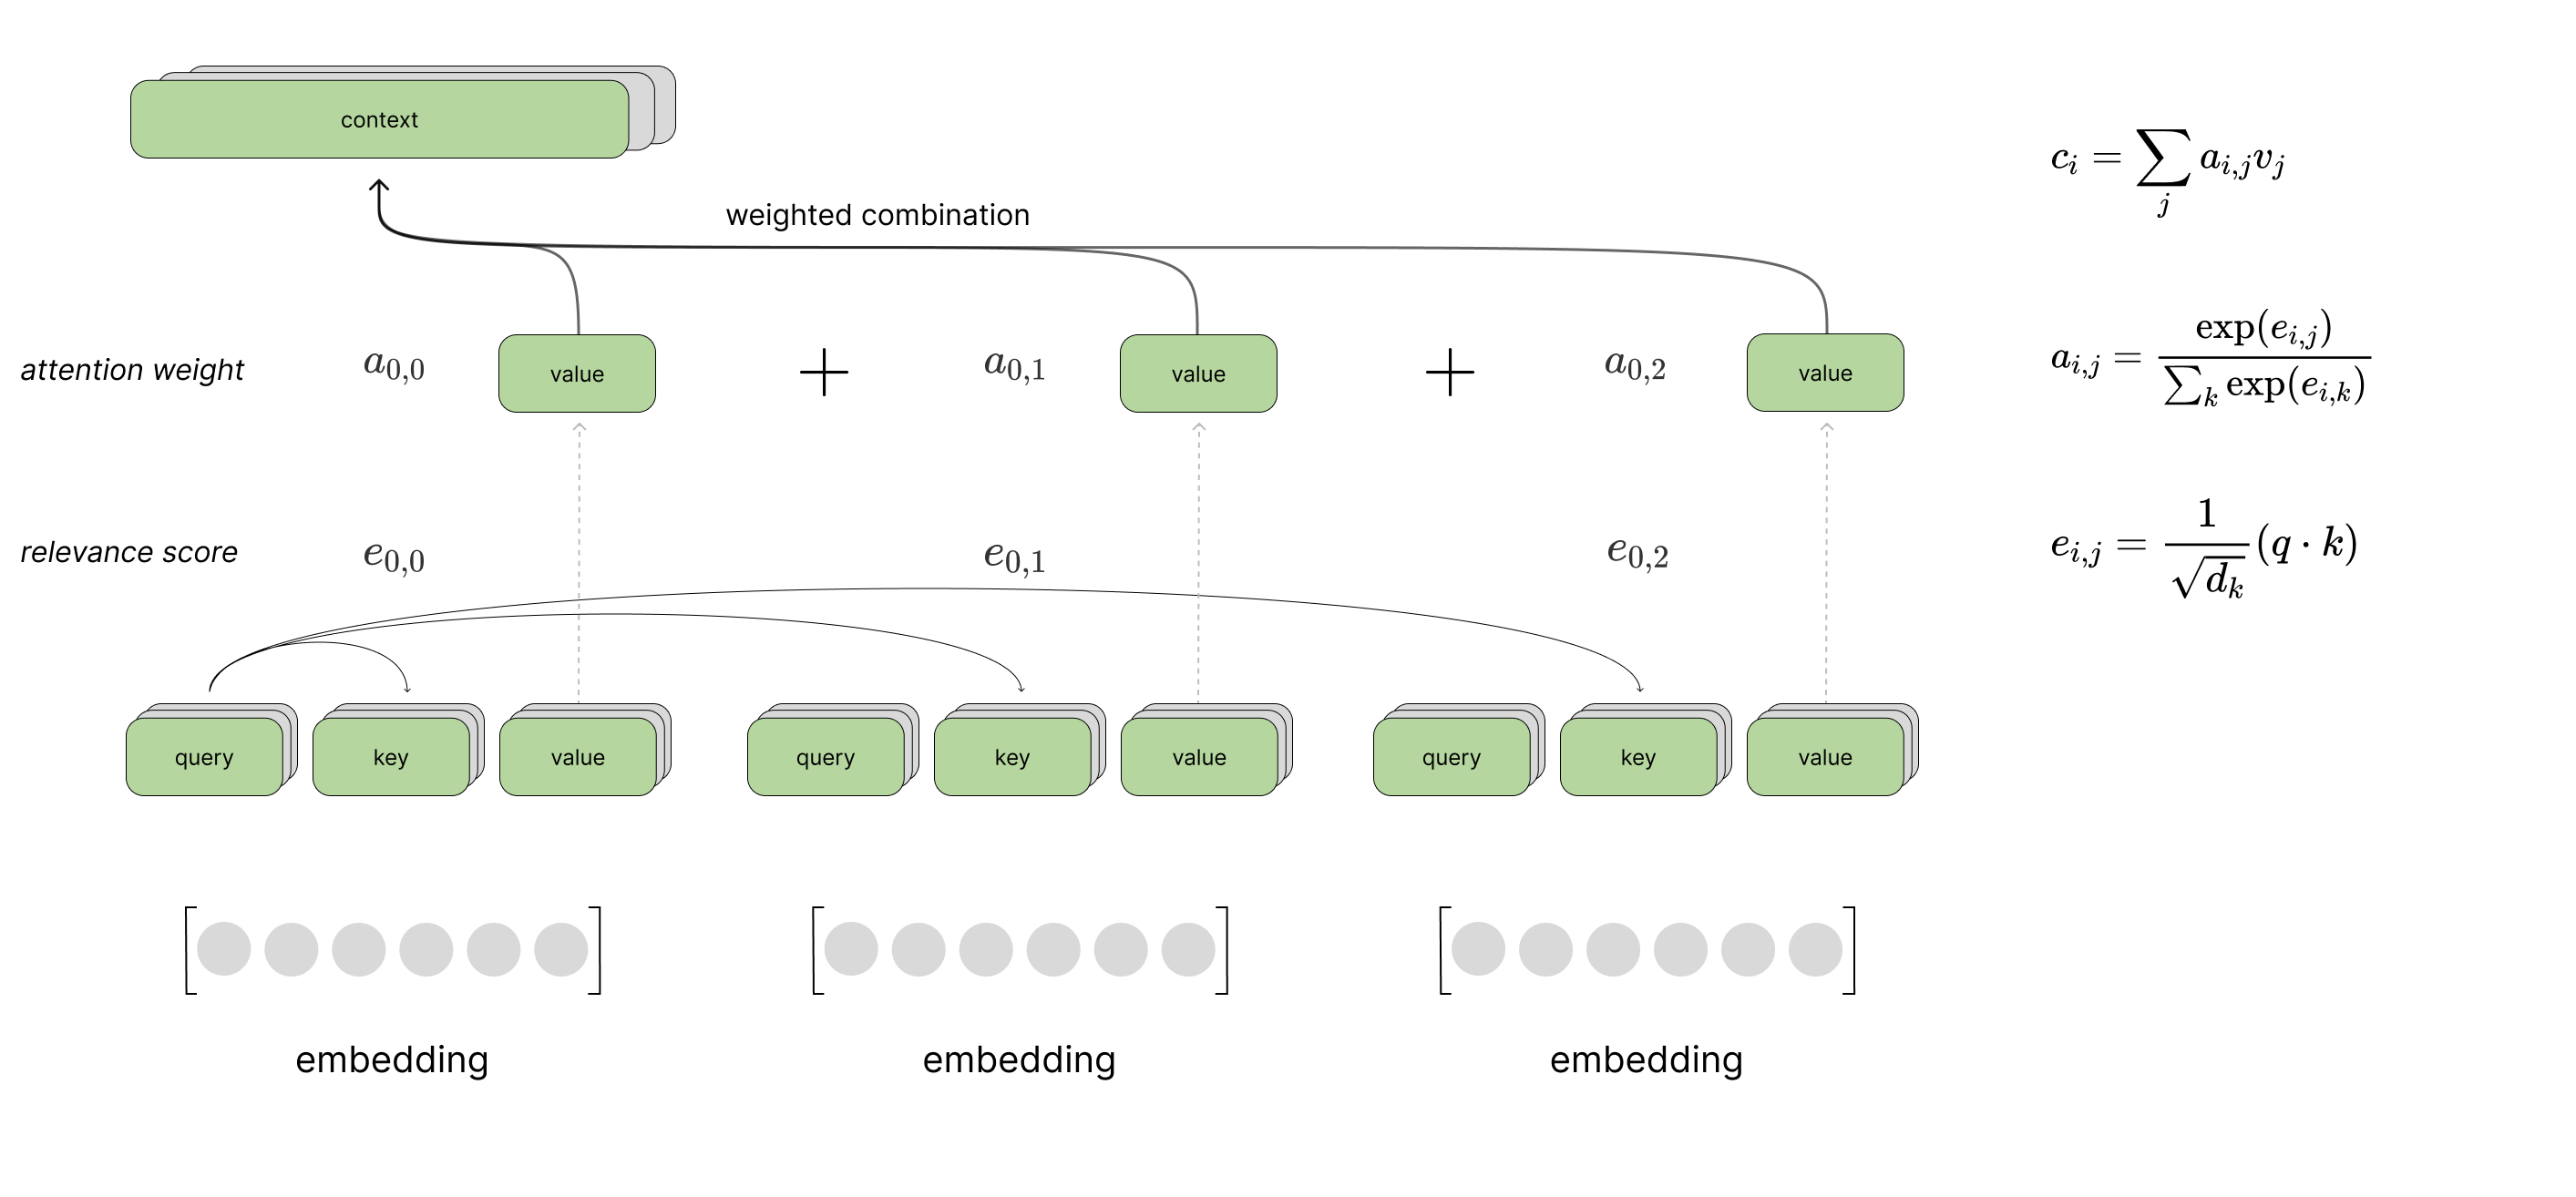

  첫 번째 쿼리와 1~3번째 단어 토큰들을 내적하고 + 스케일링 + Softmax를 적용하여 attention weight를 구합니다. 그리고 이 attention weight와 value를 곱하여 Attention output(그림에서는 context)를 만들고, 이를 concat함


## **4. Transformer 전체 아키텍쳐**

### **4-1. 트랜스포머의 전처리 단계**

**Transformer는 텍스트 입력(Inputs) → 텍스트 토큰화 (Tokenization) → 토큰 임베딩 (Embedding) → Positional Encoding**순으로 동작함.

#### **1. 토큰화 (Tokenization) : 문장을 조각내기**

- 문장을 모델이 다루는 기본단위인 **토큰**으로 자르는 것!

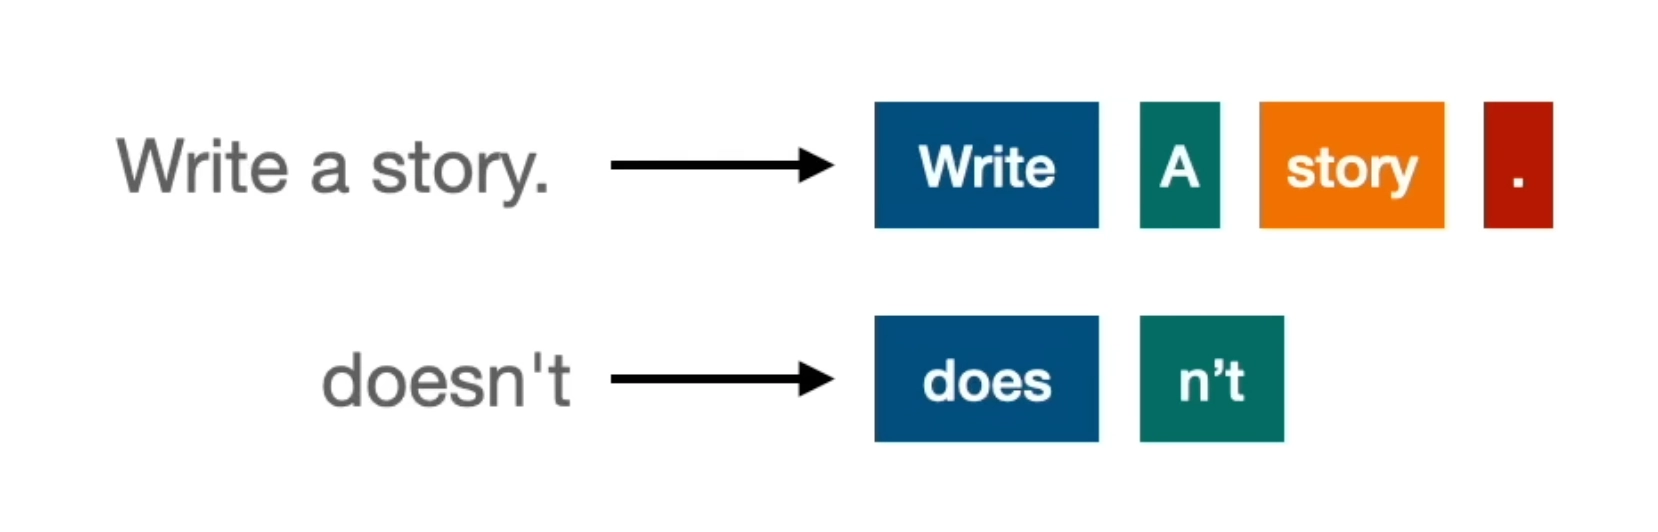

- 보통 단어 하나 = 토큰 하나: `Give`, `me`, `an` ,`apple`
- 문장 부호도 토큰: `.`, `!`
- 길거나 드문 단어는 여러 조각: `didn't` → `did` + `n't`


#### **2. 임베딩 (Embedding)  : 단어에 좌표 주기**

- 각 토큰을 **숫자(벡터)** 로 바꾸는 것! (이때 벡터의 길이 -> 벡터의 차원)

- **원리** : **단어 -> 공간적 의미**로 표현 하는 것!

**핵심원리 : 뜻이 비슷한 단어는 가까운 좌표에 놓인다!!**

- 임베딩 값은 처음엔 무작위이고, 학습하면서 점점 의미에 맞는 자리를 찾아갑니다.
- 이렇게 단어마다 기본적인 의미가 담긴 덕분에, 이후 Attention이 단어 사이의 관계를 계산할 수 있습니다.

- **Word2Vec**
  - 가장 일반적이고 강력한 임베딩 생성 방법 중 하나!
  - **단어(Word)를 벡터(Vec)로 변환한다**는 의미 담고 있음!
  - **원리**
    1. **신경망 훈련:** 신경망에 문장을 입력하고, 다음에 올 단어를 예측하도록 훈련

    2. **속성 포착:** 신경망에는 여러 층(레이어)이 있으며, 각 층은 단어의 **점점 더 깊은 속성**을 이해하려고 함.

    3. **벡터 추출:** 이때 예측을 수행하는 신경망의 마지막에서 **두 번째 레이어 (penultimate layer)**에서 나오는 숫자들을 해당 단어의 임베딩으로 사용.

    4. **심층 속성:** 마지막에서 두 번째 레이어는 단어의 **매우 심층적인 속성(pretty deep properties)**을 포착해야 하므로, 이 레이어에서 추출된 숫자 벡터는 해당 단어를 설명하는 훌륭한 임베딩이 됨!


#### **3. Positional Encoding : 순서 번호표 붙이기**

- 단어들의 순서 정보를 **임베딩 벡터에 추가하는 단계!**

- **왜 필요할까?**
  - Transformer는 모든 단어를 **한꺼번에** 보기 때문에, 그대로 두면 단어 순서를 모릅니다.
  - "개는 고양이를 쫓는다"와 "고양이는 개를 쫓는다"를 다르다고 구분하지 못하고, 같은 단어 묶음으로 봐 버립니다.
  - RNN은 순서대로 읽어서 자연스럽게 알았지만, Transformer는 순서를 **따로 알려줘야** 합니다.

- **어떻게??**
  각 위치마다 정해진 512차원 '위치 벡터'를 만들어 임베딩에 **더한다!** (이어 붙이는 게 아니라 숫자끼리 더함).
  - 이때, 1번째 자리에는 항상 벡터 A, 2번째 자리에는 항상 벡터 B…처럼 **문장이 달라도 규칙은 같아야** 모델이 순서를 배울 수 있다!
  - 같은 단어라도 자리가 다르면 최종 벡터가 달라진다!



### **4-2. 트렌스포머의 Encoder와 Decoder**

#### **Encoder : 원문을 깊이 이해하는 분석팀**

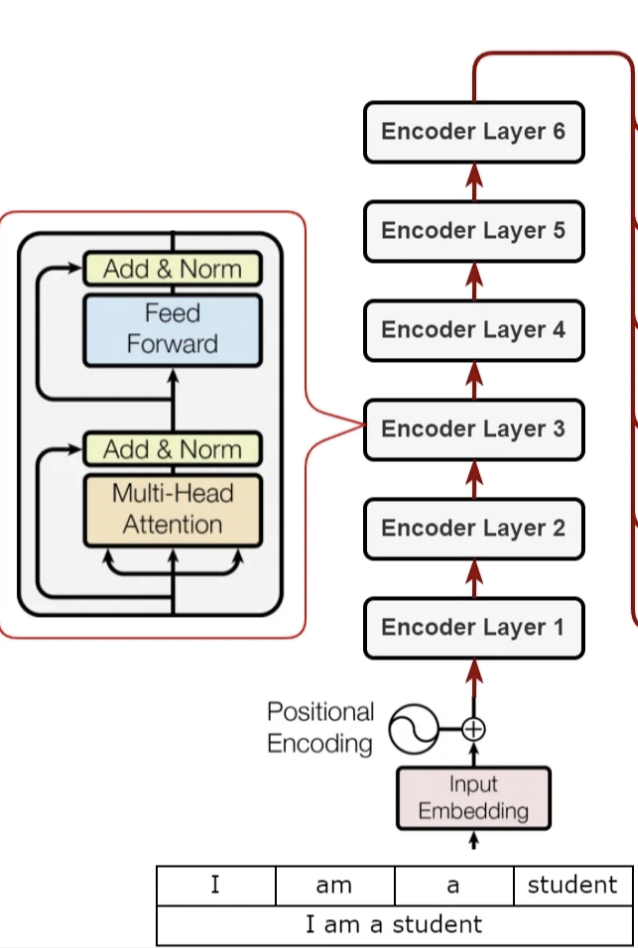

**Encoder층 하나는 두 부품으로 이루어짐!**

1. Multi-Head Self-Attention:
    
    원문 단어끼리 서로를 보며 문맥 파악
    
2. Feed-Forward Network(FFN):
    
    단어 하나하나를 따로 더 깊이 가공

  $$
\text{FFN}(x) = \max(0,\; xW_1 + b_1)\,W_2 + b_2
$$

- 512차원을 2048차원으로 **넓혔다가** 다시 512차원으로 **좁히는** 2층 신경망이고, 사이에 ReLU가 들어감.
- **단어마다 따로, 같은 가중치**로 적용. 이 단계에서는 단어끼리 정보를 주고 받지 않음.



**RNN Encoder 와의 차이**

| 구분 | RNN / LSTM Encoder | Transformer Encoder |
| --- | --- | --- |
| 읽는 방식 | 단어를 **하나씩 순서대로** | 단어를 **한꺼번에** |
| 정보 전달 | 이전 시점의 은닉 상태가 다음 시점으로 넘어감 | Self-Attention으로 모든 단어가 서로 직접 연결 |
| 순서 정보 | 읽는 순서 자체에 들어 있음 | Positional Encoding으로 따로 넣어 줌 (순서가 없기 때문) |
| 반복 단위 | RNN / LSTM 셀 | Multi-Head Attention + Feed-Forward 층 |
| 최종 출력 | 마지막 은닉 상태 하나 | **단어별 문맥 벡터 전부** |  

#### **Add & Norm: 모든 부품에 붙는 안전장치**

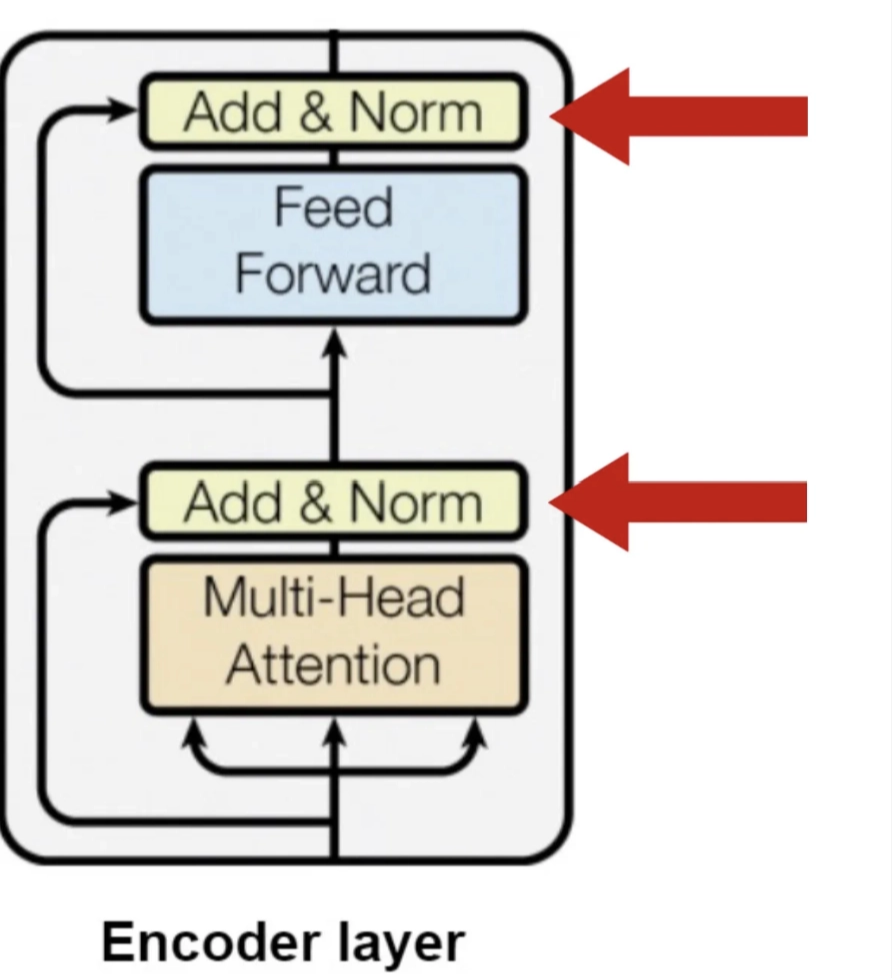


- **Add = Residual Connection (잔차 연결)**
    
    부품을 통과한 결과에 **원래 입력을 그대로 더해** 줌. 앞선 CNN 모델 중에 ResNet이라는 모델에서 나온 아이디어!
    
    → 원본은 두고 수정 사항만 덧붙인다고 생각하면 쉽다! (원본 보존, 변경 내용만 덧붙이는 방식)
    

- **Norm = Layer Normalization (층 정규화)**
    
    한 단어 벡터안의 512개 숫자를 평균 0, 분산 1 근처로 맞춤.
    
    → 마이크 볼륨 맞추기와 비슷함. 발표자마다 마이크 볼륨이 제각각이면 듣기 힘들기 때문에 볼륨을 표준 레벨로 맞춰주는 과정이라고 생각! (학습을 안정적이고 빠르게 함)



#### **Decoder : 번역문을 한 단어씩 쓰는 작성팀**

image 1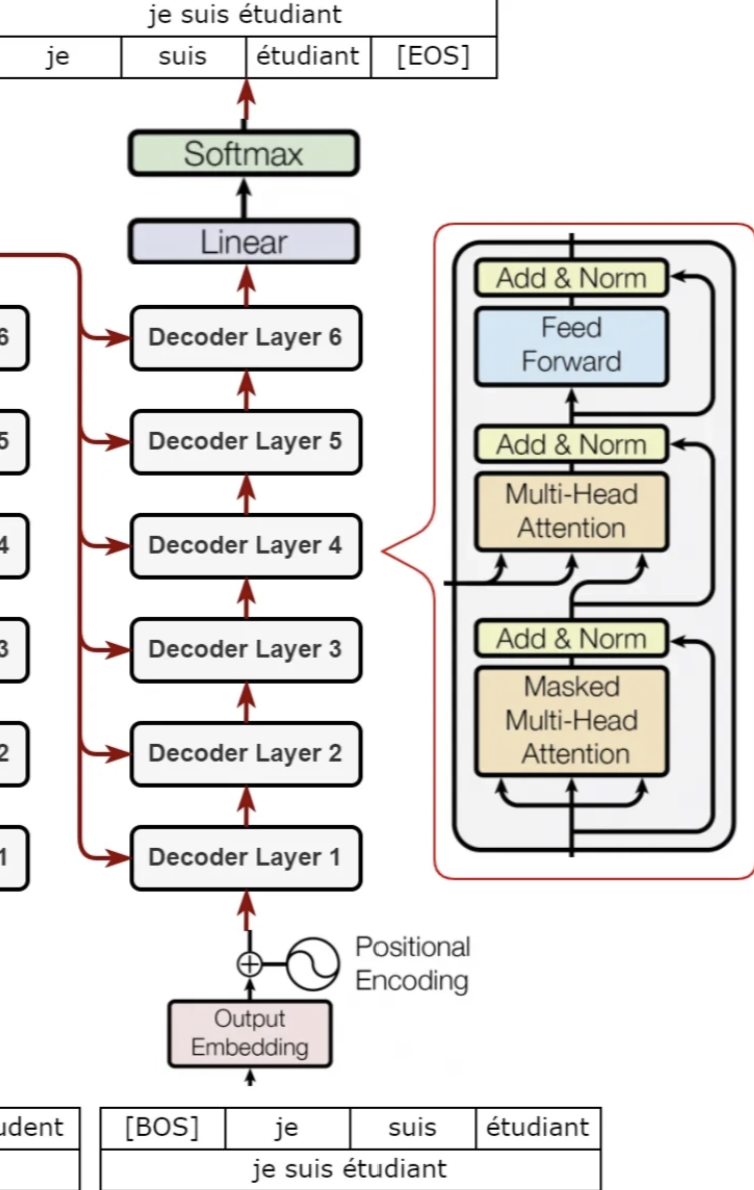

Decoder 층 하나는 세 부품으로 구성:

1. **Masked Multi-Head Self-Attention:**
    
    지금까지 쓴 번역 단어끼리 관계 파악 (미래 단어는 가림)
    
2. **Encoder-Decoder Attention (Cross-Attention):**
    
    원문 분석 자료(Encoder 출력)에서 필요한 부분 찾기
    
3. **Feed-Forward Network:**
    
    Encoder와 동일

**세 부품 뒤에도 각각 Add&Norm이 붙으며, 6층을 다 통과하면 Linear + Softmax가 다음 단어의 확률을 계산합니다.**

**Masked Multi-head Attention**
- Masked Multi-Head Attention이란?
    
    Decoder의 Self-Attention에서 **미래 시점의 단어 정보를 가려**(Softmax 후 0) **자기보다 앞의 단어만 보게 하는 메커니즘**!
    
- 역할
    
    학습 때는 정답 문장 전체를 한 번에 넣어 병렬로 학습하는데, 마스크가 없으면 답을 미리 보고 맞히는 “컨닝”이 됩니다.
    
    시험 볼 때 뒤 문제의 답안을 종이로 가려두는 것과 같다고 생각!

- 예시

  나는 학교에 간다 → I go to school

  디코더가 I go to를 입력받고 다음 단어를 예측할 때, 그 뒤에 나오는 단어인 school을 미리 보면 “컨닝”이 되기 때문에 학습이 부정확해짐.


#### **Encoder-Decoder Attention (Cross-Attention)**

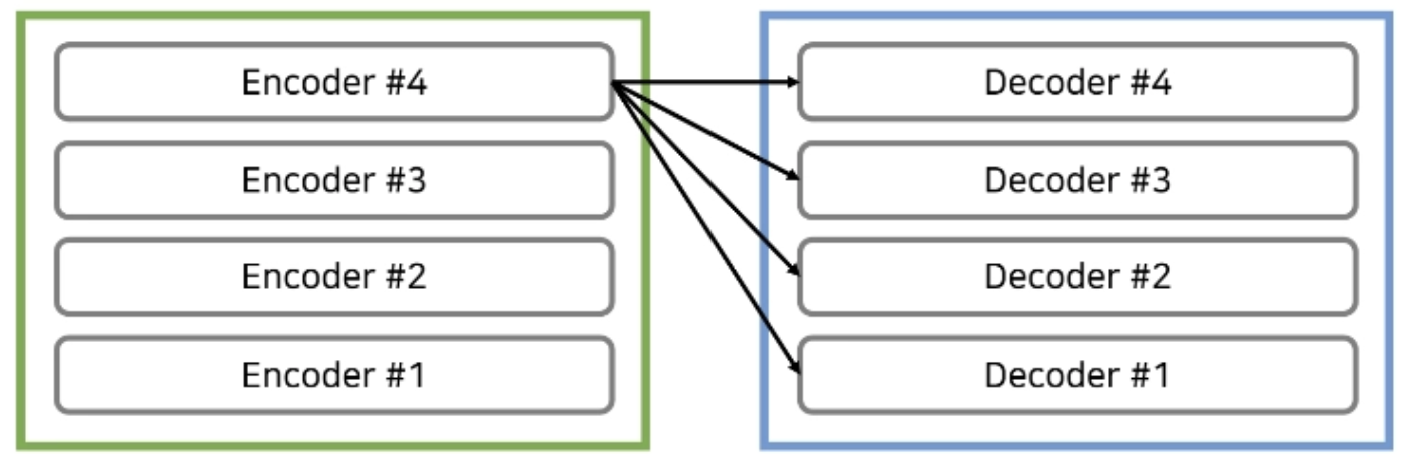

- Encoder-Decoder Attention이란?
    
    출력 문장 (Decoder)과 입력 문장 (Encoder)을 연결하는 과정입니다.
    
- Q·K·V의 출처:
    - **Q = 직전 Decoder 서브레이어의 출력**
    - **K·V = Encoder 마지막 층의 출력** (6개 디코더 레이어가 모두 같은 Encoder 출력을 씀).

- 예시

  나는 학교에 간다 -> I go to school 에서 Decoder 가 "school"을 만들 차례일 경우

    - Query: "I go to"까지의 문맥을 담은 Decoder 상태
    - Key/Value: Encoder가 "나는 학교에 간다"를 인코딩한 벡터
    - 결과: "학교" 부분에 높은 가중치를 주어, 한국어 입력의 의미와 영어 출력의 대응을 만듭니다.


### **4-3. 전체 모델 및 데이터 흐름**

#### **1. 입력 준비 : 문장을 [의미 + 위치] 벡터로 바꾸기**

- 임베딩:
    
    컴퓨터가 이해할 수 있게 ‘I’, ‘love’, ‘you’와 같은 단어들을 숫자 벡터로 바꿔주기
    
- Positional Encoding:
    
    0·1·2번 위치 벡터를 더함 → "love"는 "2번째 자리의 love"가 됨
    

| **과정** | **설명** | **예시 적용** |
| --- | --- | --- |
| **임베딩 (Embedding)** | 컴퓨터가 이해할 수 있게 단어들을 숫자 벡터로 바꿔줌 | **`I`**, **`love`**, `you`를 각각의 의미 벡터로 변환 |
| **포지셔널 인코딩** |  <u></u>단어들의 순서 정보를 임베딩 벡터에 추가하기. | `I`(1번째), `love`(2번째), `you`(3번째)에 각각 다른 위치 벡터를 더함 |


#### **2. 인코더 : 입력 문장의 [문맥적 의미] 깊이 이해하기**

- 6개 레이어를 통과하며 Multi-Head Self-Attention으로 "love"가 주어 "I", 목적어 "you"와의 관계를 흡수하고, FFN으로 다듬음!
- 인코더 레이어 1개 안에서 일어나는 일
    
    
    | 순서 | 서브레이어 | 하는 일 |
    | --- | --- | --- |
    | 1 | Multi-Head Self-Attention | 단어들이 서로를 참조해 문맥을 섞음 (“love”가 “I”, “you”를 봄) |
    | 2 | Add & Norm | 입력을 다시 더하고(잔차 연결) 값을 정규화 |
    | 3 | Feed-Forward (512 → 2048 → 512) | 각 단어 벡터를 따로따로 더 가공 |
    | 4 | Add & Norm | 다시 잔차 연결 + 정규화 |
- 출력: 문맥적 의미를 담은 벡터 → Decoder의 K·V로 전달

#### **3. 디코더 : 번역 문장을 [한 단어씩] 생성하기**

- 시작 토큰으로 시작 → Masked Self-Attention(지금까지 만든 단어만) → Cross-Attention(Encoder 출력 참조) → FFN, 이를 6층 반복
- 선형 + Softmax로 어휘 전체의 확률을 구해 가장 높은 "나는"을 출력
- "나는" → "너를"(Cross-Attention이 "you"에 집중) → "사랑해"("love"에 집중) → **“나는 당신을 사랑해” 가 나오면 종료**


| 단계 | 지금까지의 입력 | ① 내가 쓴 것 보기 (Masked Self-Attention) | ② 원문 보기 (Encoder–Decoder Attention) | 출력 |
| --- | --- | --- | --- | --- |
| Step 1 | `<start>` | 볼 수 있는 건 `<start>` 하나뿐 | "첫 단어로 뭐가 중요하지?" → **I**에 집중 | **나는** |
| Step 2 | `<start>` 나는 | `<start>`, 나는을 보고 "주어까지 썼다"는 문맥 파악 | "다음엔 뭐가 중요하지?" → **you**에 집중 | **당신을** |
| Step 3 | `<start>` 나는 당신을 | 주어와 목적어까지 썼다는 문맥 파악 | "이제 남은 건?" → **love**에 집중 | **사랑해** |
| Step 4 | `<start>` 나는 당신을 사랑해 | 문장이 완성됐다는 문맥 파악 | 원문에서 더 옮길 내용이 없음 | **`<end>`** → 종료 |


